Installing and Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

Uploading the dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving aclImdb_v1.zip to aclImdb_v1.zip


Extracting the dataset zip file

In [ ]:
import zipfile

with zipfile.ZipFile("aclImdb_v1.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

Checking weather python can see it

In [ ]:
import os

print(os.listdir("/content/aclImdb_v1"))

['aclImdb']


In [ ]:
import os

print(os.listdir("/content/aclImdb_v1/aclImdb"))

['imdbEr.txt', 'train', 'imdb.vocab', 'test', 'README']


In [ ]:
print(os.listdir("/content/aclImdb_v1/aclImdb/train"))

['unsupBow.feat', 'urls_pos.txt', 'neg', 'urls_neg.txt', 'labeledBow.feat', 'unsup', 'pos', 'urls_unsup.txt']


We get this because because the original IMDb training set contains 12,500 positive and 12,500 negative labeled reviews

In [ ]:
print(len(os.listdir("/content/aclImdb_v1/aclImdb/train/pos")))
print(len(os.listdir("/content/aclImdb_v1/aclImdb/train/neg")))

12500
12500


Going into the positive folder, reading every review, and labelling it positive and
Going into the negative folder, reading every review, and labelling it negative

In [ ]:

import os
import pandas as pd

def load_reviews(folder_path):
    reviews = []
    sentiments = []

    for sentiment in ["pos", "neg"]:
        sentiment_path = os.path.join(folder_path, sentiment)

        for filename in os.listdir(sentiment_path):
            if filename.endswith(".txt"):
                file_path = os.path.join(sentiment_path, filename)

                with open(file_path, "r", encoding="utf-8") as file:
                    review = file.read()

                reviews.append(review)

                if sentiment == "pos":
                    sentiments.append("positive")
                else:
                    sentiments.append("negative")

    return pd.DataFrame({
        "review": reviews,
        "sentiment": sentiments
    })

In [ ]:
train_df = load_reviews("/content/aclImdb_v1/aclImdb/train")
test_df = load_reviews("/content/aclImdb_v1/aclImdb/test")

Checking

In [ ]:
print(train_df.head())

                                              review sentiment
0  What can I say? I know this movie from start t...  positive
1  A famous conductor decides after a heart attac...  positive
2  I was pleased to see that she had black hair! ...  positive
3  This film is amazing and I would recommend to ...  positive
4  and this IS a very disturbing film. I may be w...  positive


Checking the size

In [ ]:
print("Training reviews:", len(train_df))
print("Testing reviews:", len(test_df))

Training reviews: 25000
Testing reviews: 25000


In [ ]:
print(train_df["sentiment"].value_counts())

sentiment
positive    12500
negative    12500
Name: count, dtype: int64


In [ ]:
print(test_df["sentiment"].value_counts())

sentiment
positive    12500
negative    12500
Name: count, dtype: int64


Keeping the official train/test split rather than immediately combining everything and doing our own 80/20 split

In [ ]:
X_train = train_df["review"]
y_train = train_df["sentiment"]

X_test = test_df["review"]
y_test = test_df["sentiment"]

Exploring the dataset

In [ ]:
train_df
test_df

,review,sentiment
0,This is sweet. The actress who played the nurs...,positive
1,This film is just plain lovely. It's funny as ...,positive
2,I have heard an awful lot about 'The English P...,positive
3,"Well, my Dad drove Lee Evans back and forth th...",positive
4,This is one of the better sci-fi series. It in...,positive
...,...,...
24995,"For me, it just didn't seem like GI Joe at all...",negative
24996,"""Quintet"" is definitely not a film most people...",negative
24997,Truly I Love Lucy as well...comedic genius yes...,negative
24998,Why did they not follow the book ... I am real...,negative


Checking dimensions

In [ ]:
print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

Training data shape: (25000, 2)
Testing data shape: (25000, 2)


Looking at sample reviews

In [ ]:
print(train_df.head())

                                              review sentiment
0  What can I say? I know this movie from start t...  positive
1  A famous conductor decides after a heart attac...  positive
2  I was pleased to see that she had black hair! ...  positive
3  This film is amazing and I would recommend to ...  positive
4  and this IS a very disturbing film. I may be w...  positive


Checking sentiment distribution

In [ ]:
print(train_df["sentiment"].value_counts())

sentiment
positive    12500
negative    12500
Name: count, dtype: int64


Visualizing the dataset "Distribution of positive and negative reviews"

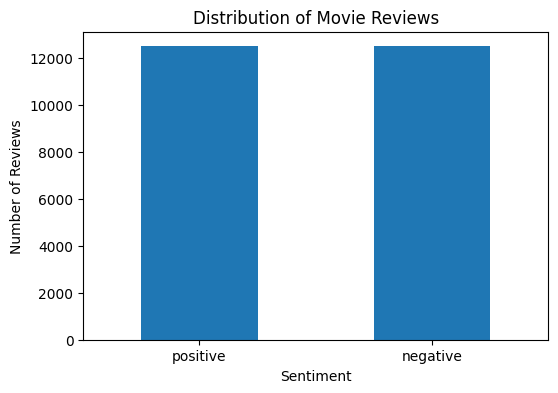

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = train_df["sentiment"].value_counts()

plt.figure(figsize=(6,4))
sentiment_counts.plot(kind="bar")
plt.title("Distribution of Movie Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

Cleaning the text

In [ ]:
import re

def clean_text(text):
    text = re.sub(r'<.*?>', '', text)
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

In [ ]:
train_df["review"] = train_df["review"].apply(clean_text)
test_df["review"] = test_df["review"].apply(clean_text)

Checking the result


In [ ]:
print(train_df["review"].iloc[0])

what can i say i know this movie from start to finish its hilarious its an strong link to my past and will change the way i view film in the future hypothetically speaking  the downfall theres no socrates johnson


For Seperation i.e. X = Reviews and Y = Sentiment


In [ ]:
X_train = train_df["review"]
y_train = train_df["sentiment"]

X_test = test_df["review"]
y_test = test_df["sentiment"]

Converting sentiments to numbers

In [ ]:
y_train = y_train.map({
    "positive": 1,
    "negative": 0
})

y_test = y_test.map({
    "positive": 1,
    "negative": 0
})

In [ ]:
print(y_train.head())

0    1
1    1
2    1
3    1
4    1
Name: sentiment, dtype: int64


In [ ]:
print(y_train.value_counts())

sentiment
1    12500
0    12500
Name: count, dtype: int64


Unigram TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_uni = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,1)
)

X_train_uni = tfidf_uni.fit_transform(X_train)
X_test_uni = tfidf_uni.transform(X_test)

In [ ]:
print(X_train_uni.shape)


(25000, 10000)


Naïve Bayes

Import

In [ ]:
from sklearn.naive_bayes import MultinomialNB

Create Model

In [ ]:
nb_uni = MultinomialNB()

Train

In [ ]:
nb_uni.fit(X_train_uni, y_train)

MultinomialNB()

Predict

In [ ]:
nb_uni_pred = nb_uni.predict(X_test_uni)

Evaluate

In [ ]:
from sklearn.metrics import accuracy_score

nb_uni_accuracy = accuracy_score(
    y_test,
    nb_uni_pred
)

print("Naive Bayes Accuracy:",
      nb_uni_accuracy)

Naive Bayes Accuracy: 0.83724


Logistic Regression

Import


In [ ]:
from sklearn.linear_model import LogisticRegression

Create

In [ ]:
lr_uni = LogisticRegression(max_iter=1000)

Train

In [ ]:
lr_uni.fit(X_train_uni, y_train)

LogisticRegression(max_iter=1000)

Predict

In [ ]:
lr_uni_pred = lr_uni.predict(X_test_uni)

Evaluate

In [ ]:
lr_uni_accuracy = accuracy_score(
    y_test,
    lr_uni_pred
)

print("Logistic Regression Accuracy:",
      lr_uni_accuracy)

Logistic Regression Accuracy: 0.88188


Linear SVM

Import


In [ ]:
from sklearn.svm import LinearSVC

Create

In [ ]:
svm_uni = LinearSVC()

Train

In [ ]:
svm_uni.fit(X_train_uni, y_train)

LinearSVC()

Predict

In [ ]:
svm_uni_pred = svm_uni.predict(X_test_uni)

Evaluate

In [ ]:
svm_uni_accuracy = accuracy_score(
    y_test,
    svm_uni_pred
)

print("SVM Accuracy:", svm_uni_accuracy)

SVM Accuracy: 0.87124


Comparing the 3 models

In [ ]:
uni_results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy": [
        nb_uni_accuracy,
        lr_uni_accuracy,
        svm_uni_accuracy
    ]
})

print(uni_results)

                 Model  Accuracy
0          Naive Bayes   0.83724
1  Logistic Regression   0.88188
2           Linear SVM   0.87124


Accuracy Graph

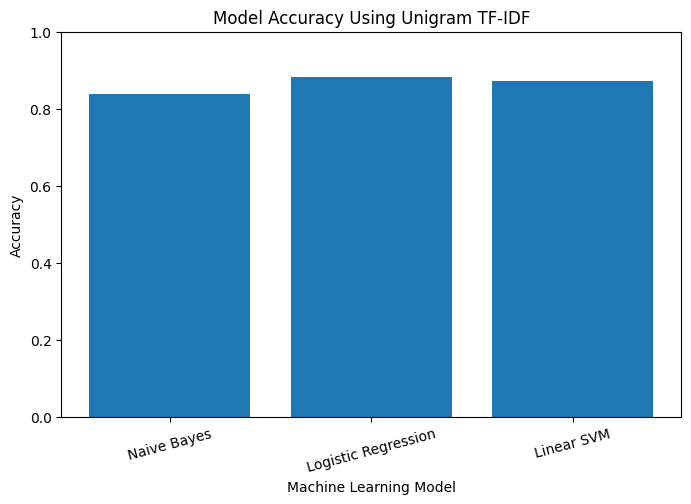

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    uni_results["Model"],
    uni_results["Accuracy"]
)

plt.title("Model Accuracy Using Unigram TF-IDF")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0,1)
plt.xticks(rotation=15)

plt.show()

Creating a second TF - IDF


In [ ]:
tfidf_bigram = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2)
)

In [ ]:
X_train_bigram = tfidf_bigram.fit_transform(X_train)

X_test_bigram = tfidf_bigram.transform(X_test)

Checking

In [ ]:
print(X_train_bigram.shape)

(25000, 10000)


Training the 3 models again

Naïve Bayes

In [ ]:
nb_bigram = MultinomialNB()

nb_bigram.fit(
    X_train_bigram,
    y_train
)

nb_bigram_pred = nb_bigram.predict(
    X_test_bigram
)

nb_bigram_accuracy = accuracy_score(
    y_test,
    nb_bigram_pred
)

Logistic Regression

In [ ]:
lr_bigram = LogisticRegression(
    max_iter=1000
)

lr_bigram.fit(
    X_train_bigram,
    y_train
)

lr_bigram_pred = lr_bigram.predict(
    X_test_bigram
)

lr_bigram_accuracy = accuracy_score(
    y_test,
    lr_bigram_pred
)

SVM

In [ ]:
svm_bigram = LinearSVC()

svm_bigram.fit(
    X_train_bigram,
    y_train
)

svm_bigram_pred = svm_bigram.predict(
    X_test_bigram
)

svm_bigram_accuracy = accuracy_score(
    y_test,
    svm_bigram_pred
)

Final Comparison combining everything

In [ ]:
final_results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM"
    ],

    "Unigram Accuracy": [
        nb_uni_accuracy,
        lr_uni_accuracy,
        svm_uni_accuracy
    ],

    "Unigram + Bigram Accuracy": [
        nb_bigram_accuracy,
        lr_bigram_accuracy,
        svm_bigram_accuracy
    ]
})

print(final_results)

                 Model  Unigram Accuracy  Unigram + Bigram Accuracy
0          Naive Bayes           0.83724                    0.86044
1  Logistic Regression           0.88188                    0.89056
2           Linear SVM           0.87124                    0.88184


Plotting the final comparison

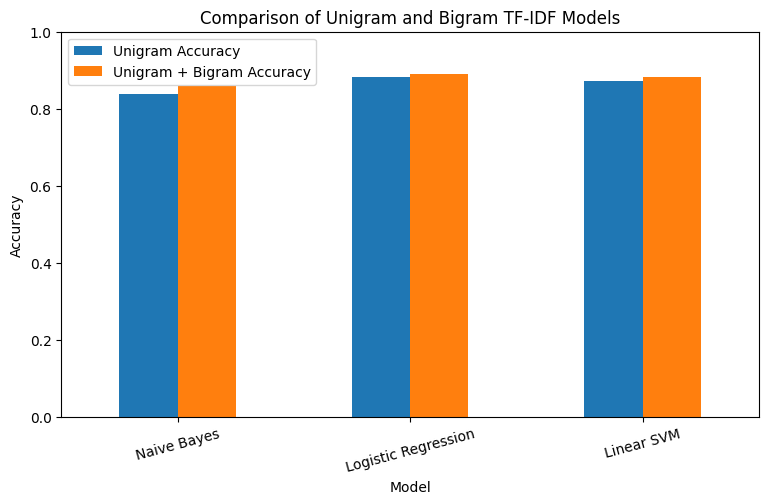

In [ ]:
final_results.set_index("Model").plot(
    kind="bar",
    figsize=(9,5)
)

plt.title(
    "Comparison of Unigram and Bigram TF-IDF Models"
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0,1)

plt.xticks(rotation=15)

plt.show()

For SVM

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    y_test,
    svm_bigram_pred
)

precision = precision_score(
    y_test,
    svm_bigram_pred
)

recall = recall_score(
    y_test,
    svm_bigram_pred
)

f1 = f1_score(
    y_test,
    svm_bigram_pred
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.88184
Precision: 0.880500637755102
Recall   : 0.8836
F1 Score : 0.8820475962306341


Classification report

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        svm_bigram_pred,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88     12500
    Positive       0.88      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



Confusion Matrix

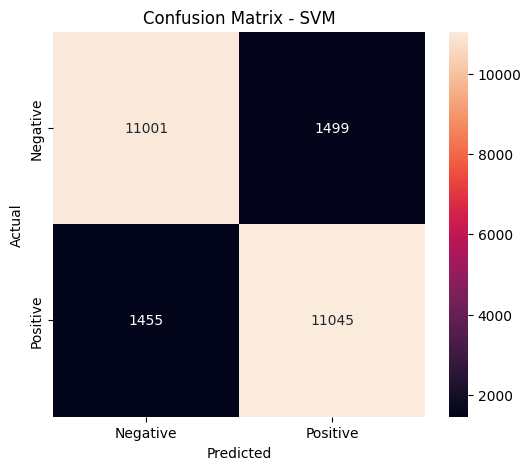

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_test,
    svm_bigram_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVM")

plt.show()

Selecting the best performing model

In [ ]:
best_model = final_results.loc[
    final_results["Unigram + Bigram Accuracy"].idxmax()
]

print(best_model)

Model                        Logistic Regression
Unigram Accuracy                         0.88188
Unigram + Bigram Accuracy                0.89056
Name: 1, dtype: object


Creating the prediction function


In [ ]:
def predict_sentiment(review):
    review = clean_text(review)

    review_vector = tfidf_bigram.transform([review])

    prediction = lr_bigram.predict(review_vector)

    if prediction[0] == 1:
        return "POSITIVE 😊"
    else:
        return "NEGATIVE 😞"

Testing one review

In [ ]:
review = input("Enter a movie review: ")

print(predict_sentiment(review))

Enter a movie review: The movie was incredible! Overall a good movie.
POSITIVE 😊


Testing the second review


In [ ]:
review = input("Enter a movie review: ")

print(predict_sentiment(review))

Enter a movie review: The movie was boring, poorly acted and a complete waste of time.
NEGATIVE 😞


Testing multiple reviews

In [ ]:
test_reviews = [
    "This movie was absolutely fantastic and brilliant.",
    "The acting was terrible and the story was boring.",
    "I loved every minute of this wonderful movie.",
    "This was one of the worst movies I have ever seen.",
    "The movie was okay but nothing special."
]

for review in test_reviews:
    print("Review:", review)
    print("Prediction:", predict_sentiment(review))
    print()

Review: This movie was absolutely fantastic and brilliant.
Prediction: POSITIVE 😊

Review: The acting was terrible and the story was boring.
Prediction: NEGATIVE 😞

Review: I loved every minute of this wonderful movie.
Prediction: POSITIVE 😊

Review: This was one of the worst movies I have ever seen.
Prediction: NEGATIVE 😞

Review: The movie was okay but nothing special.
Prediction: NEGATIVE 😞



Building a small GUI using Gradio

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr

def predict_sentiment(review):
    review = clean_text(review)

    review_vector = tfidf_bigram.transform([review])

    prediction = lr_bigram.predict(review_vector)

    if prediction[0] == 1:
        return "POSITIVE 😊"
    else:
        return "NEGATIVE 😞"


demo = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(
        lines=5,
        placeholder="Enter a movie review here..."
    ),
    outputs=gr.Textbox(label="Predicted Sentiment"),
    title="🎬 Movie Review Sentiment Analysis",
    description="Enter a movie review to predict whether it is Positive or Negative."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a2b1c16a11d0850c06.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Using joblib to save our trained model

In [ ]:
import joblib

joblib.dump(
    svm_bigram,
    "sentiment_model.pkl"
)

joblib.dump(
    tfidf_bigram,
    "tfidf_vectorizer.pkl"
)

['tfidf_vectorizer.pkl']